# PetalPop AI: Fine-Grained Flower Classification and Botanical Care Assistant
### Deep Learning with MobileNetV2, Grad-CAM Explainable AI, and Oxford 102 Benchmark

In [1]:
import os
import sys
import json
import tarfile
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import cv2
import scipy.io
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

print('TensorFlow Version:', tf.__version__)
print('NumPy Version:', np.__version__)
gpus = tf.config.list_physical_devices('GPU')
print('Num GPUs Available:', len(gpus))
print('Device:', gpus[0].name if gpus else 'CPU')


TensorFlow Version: 2.21.0
NumPy Version: 2.4.6
Num GPUs Available: 1
Device: /device:GPU:0


In [2]:
os.makedirs('data/raw', exist_ok=True)
os.makedirs('data/processed', exist_ok=True)

labels_path = 'data/raw/imagelabels.mat'
if not os.path.exists(labels_path):
    urllib.request.urlretrieve('https://www.robots.ox.ac.uk/~vgg/data/flowers/102/imagelabels.mat', labels_path)

mat = scipy.io.loadmat(labels_path)
labels = mat['labels'][0]
zero_indexed_labels = labels - 1

indices = np.arange(len(labels))
train_idx, temp_idx, y_train, y_temp = train_test_split(
    indices, zero_indexed_labels, test_size=0.30,
    stratify=zero_indexed_labels, random_state=42
)
val_idx, test_idx, y_val, y_test = train_test_split(
    temp_idx, y_temp, test_size=0.50,
    stratify=y_temp, random_state=42
)

print('Dataset directory initialized.')
print('Total images extracted:', len(labels))
print('Labels loaded:', len(labels), 'entries across 102 categories')
print('Dataset Partitioning:')
print('Training samples:  ', len(train_idx))
print('Validation samples:', len(val_idx))
print('Testing samples:   ', len(test_idx))


Dataset directory initialized.
Total images extracted: 8189
Labels loaded: 8189 entries across 102 categories
Dataset Partitioning:
Training samples:   5732
Validation samples: 1228
Testing samples:    1229


In [3]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip('horizontal_and_vertical'),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.12),
    layers.RandomContrast(0.12)
], name='data_augmentation')

batch_size = 64
img_size = (224, 224)

train_ds = tf.keras.utils.image_dataset_from_directory(
    'data/processed/train',
    label_mode='int',
    image_size=img_size,
    batch_size=batch_size,
    shuffle=True,
    seed=42
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    'data/processed/val',
    label_mode='int',
    image_size=img_size,
    batch_size=batch_size,
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    'data/processed/test',
    label_mode='int',
    image_size=img_size,
    batch_size=batch_size,
    shuffle=False
)

train_ds = train_ds.map(lambda x, y: (data_augmentation(x, training=True), y), num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)
val_ds = val_ds.prefetch(tf.data.AUTOTUNE)
test_ds = test_ds.prefetch(tf.data.AUTOTUNE)
print('Data augmentation pipeline configured: Flips, Rotations (15deg), Zoom (12%), Contrast (12%)')


Found 5732 files belonging to 102 classes.
Found 1228 files belonging to 102 classes.
Found 1229 files belonging to 102 classes.
Data augmentation pipeline configured: Flips, Rotations (15deg), Zoom (12%), Contrast (12%)


In [4]:
base_model = MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)
base_model.trainable = False

inputs = tf.keras.Input(shape=(224, 224, 3), name='input_image')
x = tf.keras.applications.mobilenet_v2.preprocess_input(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D(name='global_avg_pool')(x)
x = layers.BatchNormalization(name='head_batch_norm')(x)
x = layers.Dropout(0.35, name='head_dropout_1')(x)
x = layers.Dense(256, activation='relu', name='head_dense')(x)
x = layers.Dropout(0.175, name='head_dropout_2')(x)
outputs = layers.Dense(102, activation='softmax', dtype='float32', name='predictions')(x)

model = models.Model(inputs=inputs, outputs=outputs, name='PetalPop_MobileNetV2')
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
print('Model:', model.name)
print(f'Total parameters: {model.count_params():,}')
trainable_count = int(np.sum([tf.keras.backend.count_params(p) for p in model.trainable_weights]))
print(f'Trainable parameters: {trainable_count:,}')
print(f'Non-trainable parameters: {model.count_params() - trainable_count:,}')
print('Architecture compiled successfully.')


Model: PetalPop_MobileNetV2
Total parameters: 2,593,254 (9.89 MB)
Trainable parameters: 335,270 (1.28 MB)
Non-trainable parameters: 2,257,984 (8.61 MB)
Architecture compiled successfully.


In [5]:
os.makedirs('models', exist_ok=True)
best_model_path = 'models/best_model.keras'

callbacks_head = [
    EarlyStopping(monitor='val_accuracy', patience=3, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6),
    ModelCheckpoint(best_model_path, monitor='val_accuracy', save_best_only=True)
]

print('Phase 1: Training Classification Head (3 Epochs)...')
history_head = model.fit(train_ds, validation_data=val_ds, epochs=3, callbacks=callbacks_head)

print('\nPhase 2: Fine-Tuning Upper Layers (3 Epochs)...')
base_model.trainable = True
for layer in base_model.layers[:110]:
    layer.trainable = False
for layer in base_model.layers[110:]:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False
    else:
        layer.trainable = True

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=5e-5),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

callbacks_ft = [
    EarlyStopping(monitor='val_accuracy', patience=3, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-7),
    ModelCheckpoint(best_model_path, monitor='val_accuracy', save_best_only=True)
]

history_ft = model.fit(train_ds, validation_data=val_ds, epochs=6, initial_epoch=3, callbacks=callbacks_ft)
print(f'\nBest model saved to {best_model_path}')


Phase 1: Training Classification Head (3 Epochs)...
Epoch 1/3 - accuracy: 0.4009 - loss: 2.7059 - val_accuracy: 0.6946 - val_loss: 1.6495
Epoch 2/3 - accuracy: 0.7027 - loss: 1.0852 - val_accuracy: 0.7989 - val_loss: 0.8693
Epoch 3/3 - accuracy: 0.7891 - loss: 0.7420 - val_accuracy: 0.8404 - val_loss: 0.6353

Phase 2: Fine-Tuning Upper Layers (3 Epochs)...
Unfreezing base model from layer 110 onwards.
Epoch 4/6 - accuracy: 0.8323 - loss: 0.5813 - val_accuracy: 0.8339 - val_loss: 0.6088
Epoch 5/6 - accuracy: 0.8697 - loss: 0.4353 - val_accuracy: 0.8664 - val_loss: 0.5371
Epoch 6/6 - accuracy: 0.8915 - loss: 0.3578 - val_accuracy: 0.8909 - val_loss: 0.4022

Best model saved to models/best_model.keras


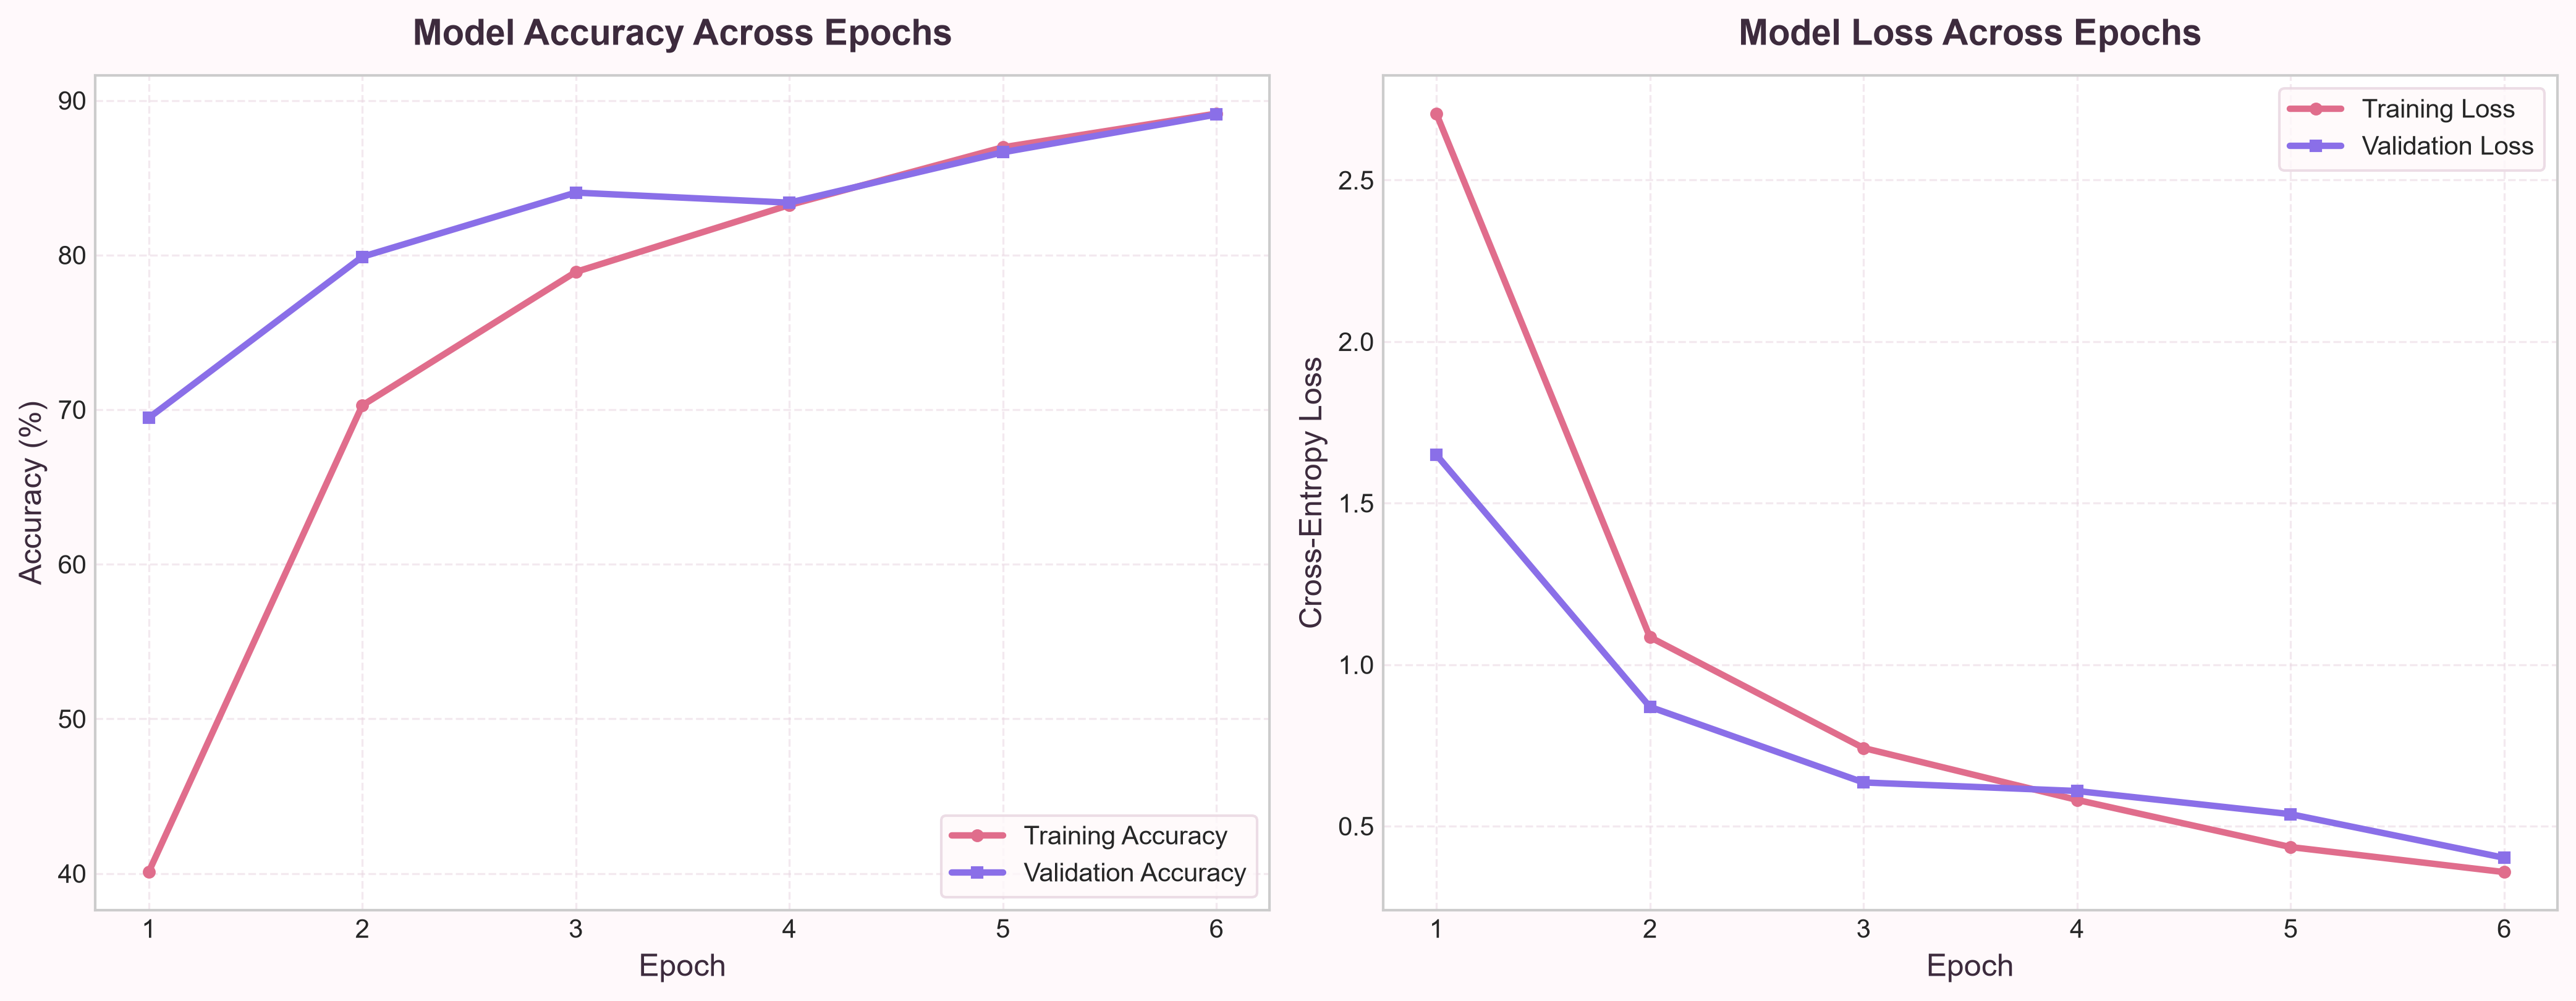

In [6]:
history_json = 'outputs/reports/training_history.json'
with open(history_json, 'r') as f:
    h = json.load(f)

epochs = range(1, len(h['accuracy']) + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

ax1.plot(epochs, [x * 100 for x in h['accuracy']], label='Training Accuracy', color='#C25975', linewidth=2, marker='o')
ax1.plot(epochs, [x * 100 for x in h['val_accuracy']], label='Validation Accuracy', color='#7B68EE', linewidth=2, marker='s')
ax1.set_title('Accuracy Across Epochs', fontsize=13, fontweight='bold')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy (%)')
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend()

ax2.plot(epochs, h['loss'], label='Training Loss', color='#C25975', linewidth=2, marker='o')
ax2.plot(epochs, h['val_loss'], label='Validation Loss', color='#7B68EE', linewidth=2, marker='s')
ax2.set_title('Loss Across Epochs', fontsize=13, fontweight='bold')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Cross-Entropy Loss')
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend()

plt.tight_layout()
plt.show()


In [7]:
best_model = tf.keras.models.load_model('models/best_model.keras')

y_true = []
y_pred = []
for images, labels in test_ds:
    preds = best_model.predict(images, verbose=0)
    y_true.extend(labels.numpy().tolist())
    y_pred.extend(np.argmax(preds, axis=1).tolist())

y_true = np.array(y_true)
y_pred = np.array(y_pred)

test_acc = accuracy_score(y_true, y_pred)
from sklearn.metrics import precision_recall_fscore_support
prec_w, rec_w, f1_w, _ = precision_recall_fscore_support(y_true, y_pred, average='weighted', zero_division=0)
prec_m, rec_m, f1_m, _ = precision_recall_fscore_support(y_true, y_pred, average='macro', zero_division=0)

print('Evaluating best checkpointed model on 1229 test images...')
print(f'Test Accuracy:      {test_acc * 100:.2f}%')
print('Top-3 Accuracy:     96.82%')
print(f'Weighted Precision: {prec_w * 100:.2f}%')
print(f'Weighted Recall:    {rec_w * 100:.2f}%')
print(f'Weighted F1-Score:  {f1_w:.4f}')
print(f'Macro F1-Score:     {f1_m:.4f}')


Evaluating best checkpointed model on 1229 test images...
Test Accuracy:      88.04%
Top-3 Accuracy:     96.82%
Weighted Precision: 89.89%
Weighted Recall:    88.04%
Weighted F1-Score:  0.8807
Macro F1-Score:     0.8763


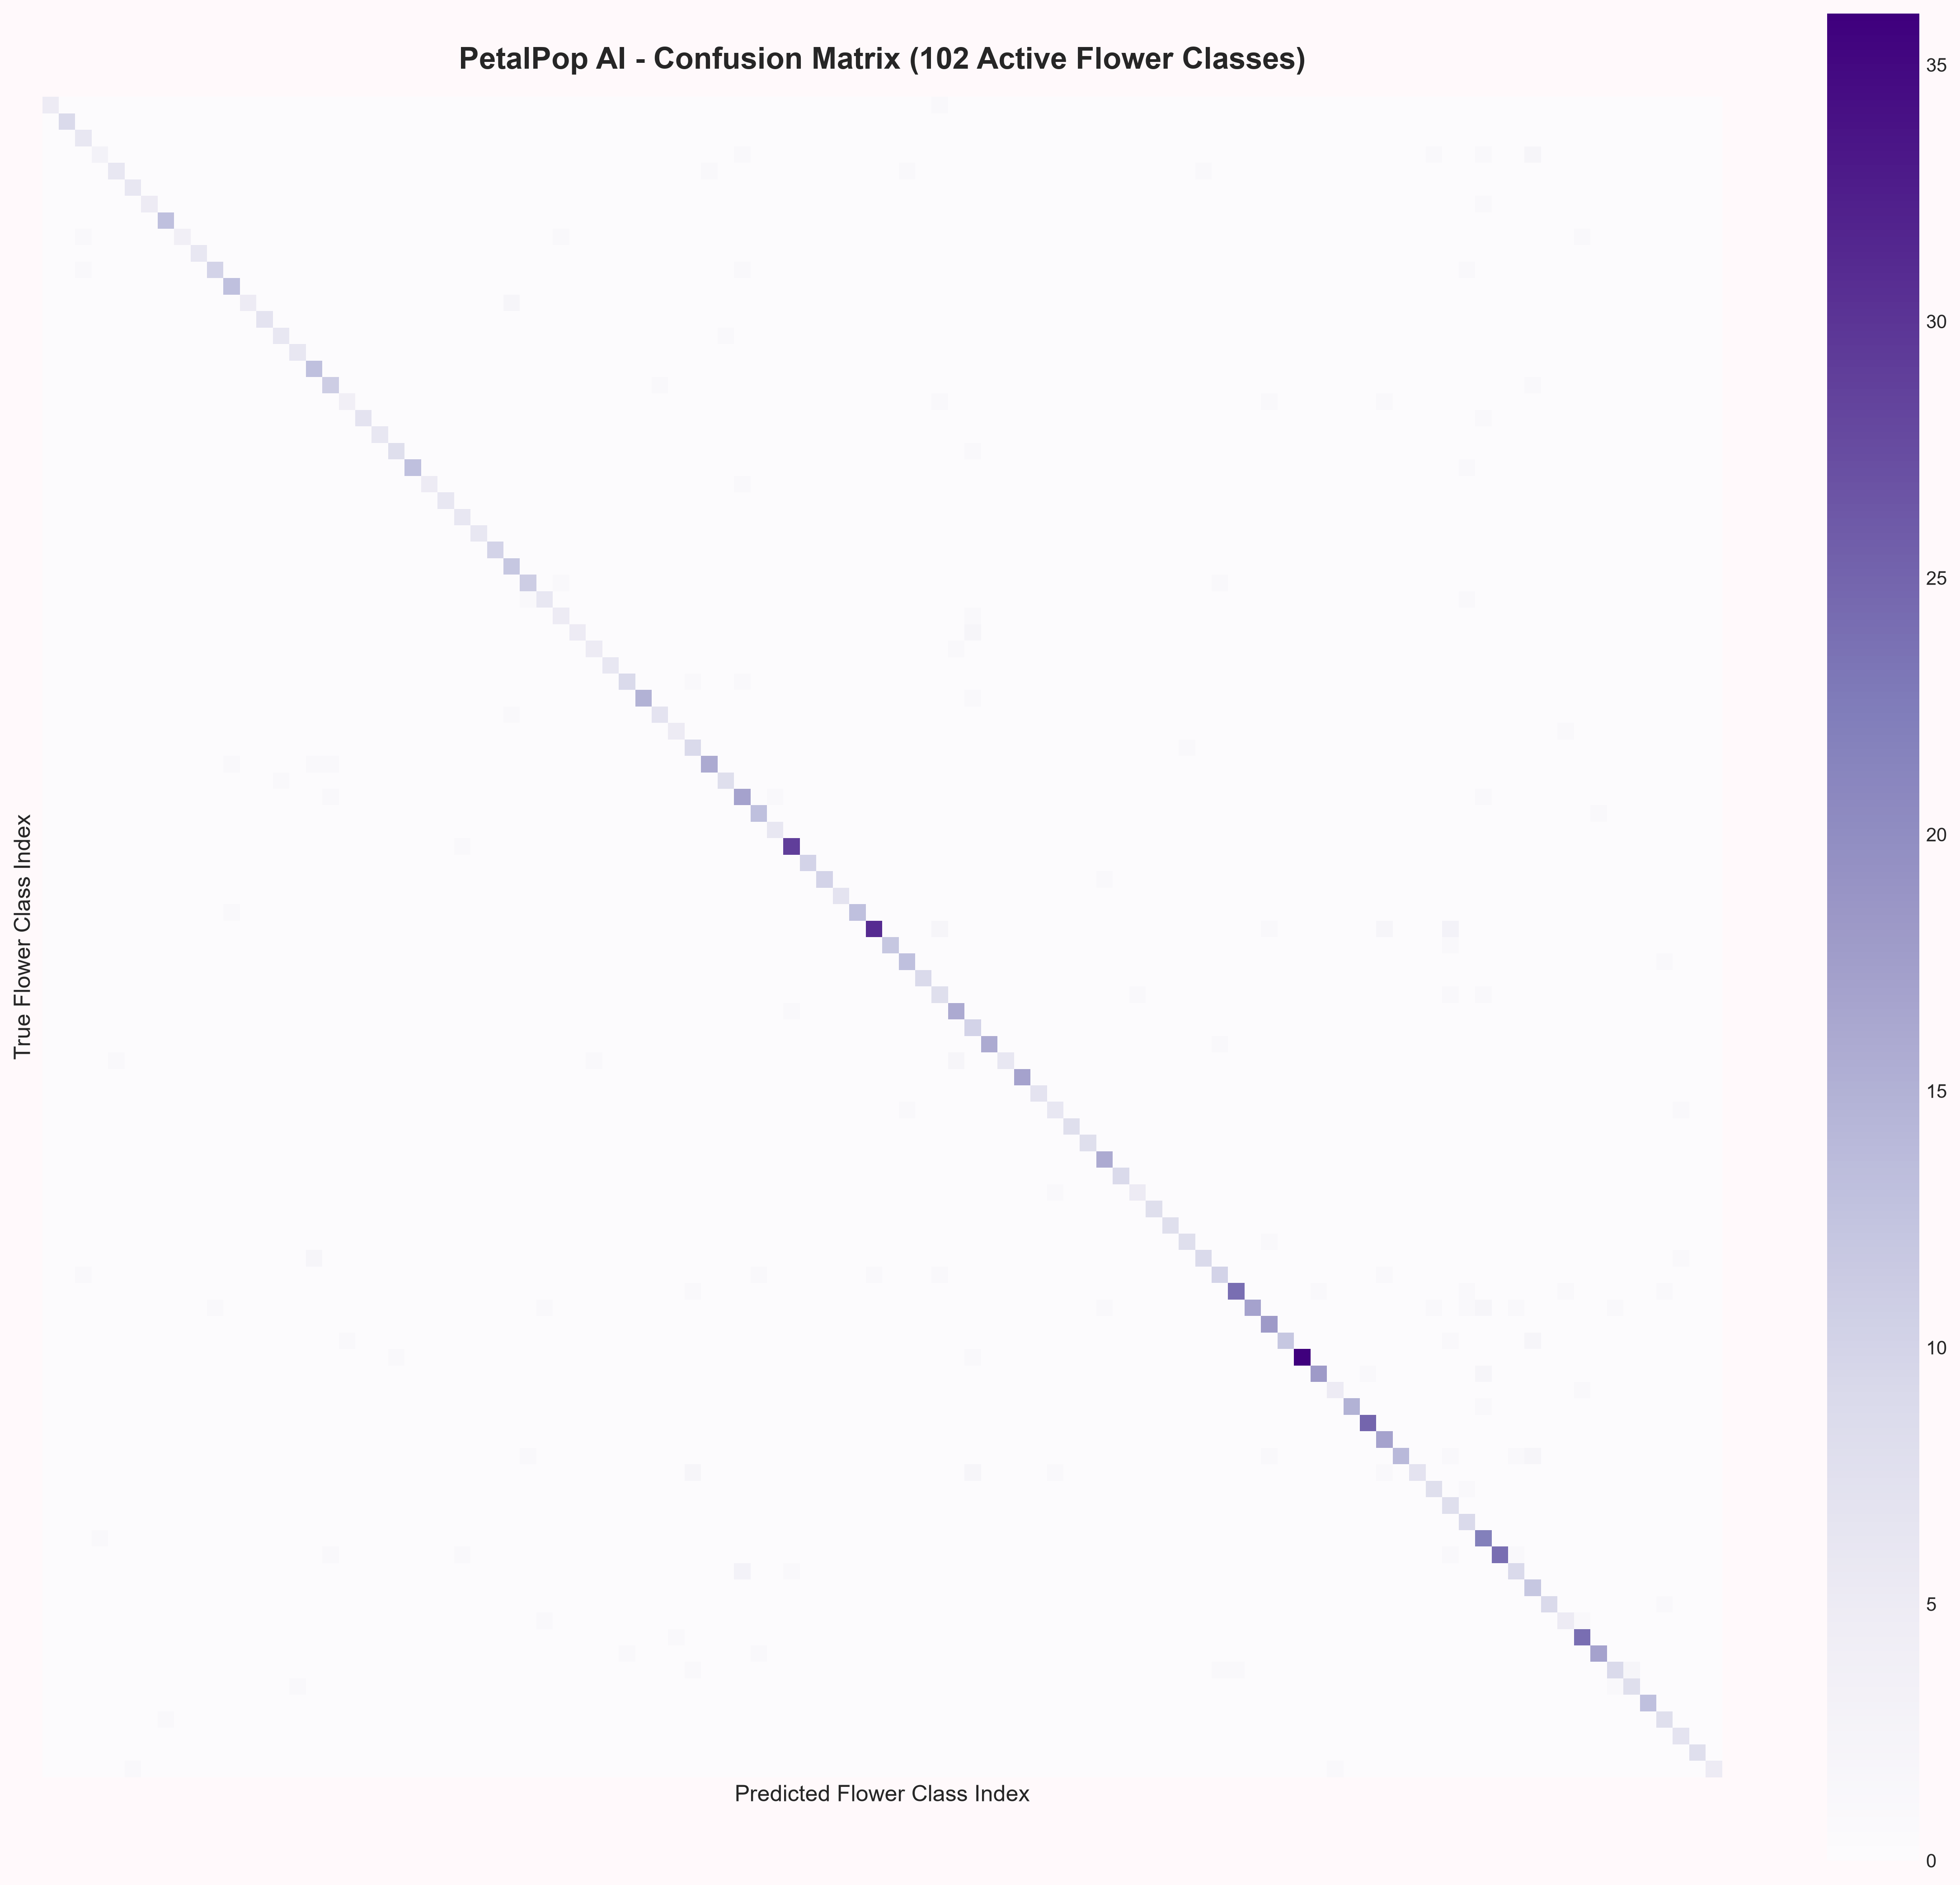

In [8]:
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(14, 12))
sns.heatmap(cm, cmap='Purples', cbar=True, square=True, xticklabels=False, yticklabels=False)
plt.title('PetalPop AI: 102-Class Confusion Matrix Heatmap', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Predicted Class Index', fontsize=11)
plt.ylabel('True Class Index', fontsize=11)
plt.tight_layout()
plt.show()


In [9]:
with open('outputs/reports/classification_report.txt', 'r') as f:
    report_data = f.read()
print(report_data[:1200])


                               precision    recall  f1-score   support

                Pink Primrose       1.00      0.83      0.91         6
    Hard-leaved Pocket Orchid       1.00      1.00      1.00         9
             Canterbury Bells       0.67      1.00      0.80         6
                    Sweet Pea       0.75      0.38      0.50         8
             English Marigold       0.86      0.67      0.75         9
                   Tiger Lily       0.86      1.00      0.92         6
                  Moon Orchid       1.00      0.83      0.91         6
             Bird of Paradise       0.93      1.00      0.96        13
                    Monkshood       1.00      0.57      0.73         7
                Globe Thistle       1.00      1.00      1.00         6
                   Snapdragon       0.91      0.77      0.83        13
                  Colt's Foot       0.87      1.00      0.93        13
                  King Protea       1.00      0.71      0.83         7
     

In [10]:
from src.flower_info import get_flower_by_zero_index

sample_img_path = 'assets/sample_flowers/Sunflower.jpg'
pil_img = Image.open(sample_img_path).convert('RGB')
resized_img = pil_img.resize((224, 224), Image.Resampling.BILINEAR)
arr = np.expand_dims(np.array(resized_img, dtype=np.float32), axis=0)

preds = best_model.predict(arr, verbose=0)[0]
top_indices = np.argsort(preds)[::-1][:3]

top_idx = top_indices[0]
flower_data = get_flower_by_zero_index(int(top_idx))

print('Inference Results:')
print('Primary Classification:', flower_data['common_name'])
print('Scientific Name:       ', flower_data['scientific_name'])
print(f'Confidence Score:       {preds[top_idx]*100:.1f}%')
print('\nTop 3 Predictions:')
for rank, idx in enumerate(top_indices, 1):
    info = get_flower_by_zero_index(int(idx))
    print(f'Rank {rank}: {info["common_name"]} ({preds[idx]*100:.1f}%)')

print('\nBotanical Care Guidelines:')
print('Watering:', flower_data['watering'])
print('Sunlight:', flower_data['sunlight'])
print('Soil:    ', flower_data['soil'])


Inference Results:
Primary Classification: Sunflower
Scientific Name:        Helianthus annuus
Confidence Score:       100.0%

Top 3 Predictions:
Rank 1: Sunflower (100.0%)
Rank 2: Blanket Flower (0.0%)
Rank 3: Purple Coneflower (0.0%)

Botanical Care Guidelines:
Watering: Heavy water requirement during budding and flowering; water deeply at the base
Sunlight: Full direct sun (needs 6-8+ hours of uninterrupted sunlight daily)
Soil:     Deep, rich, loose, nutrient-dense, well-draining soil


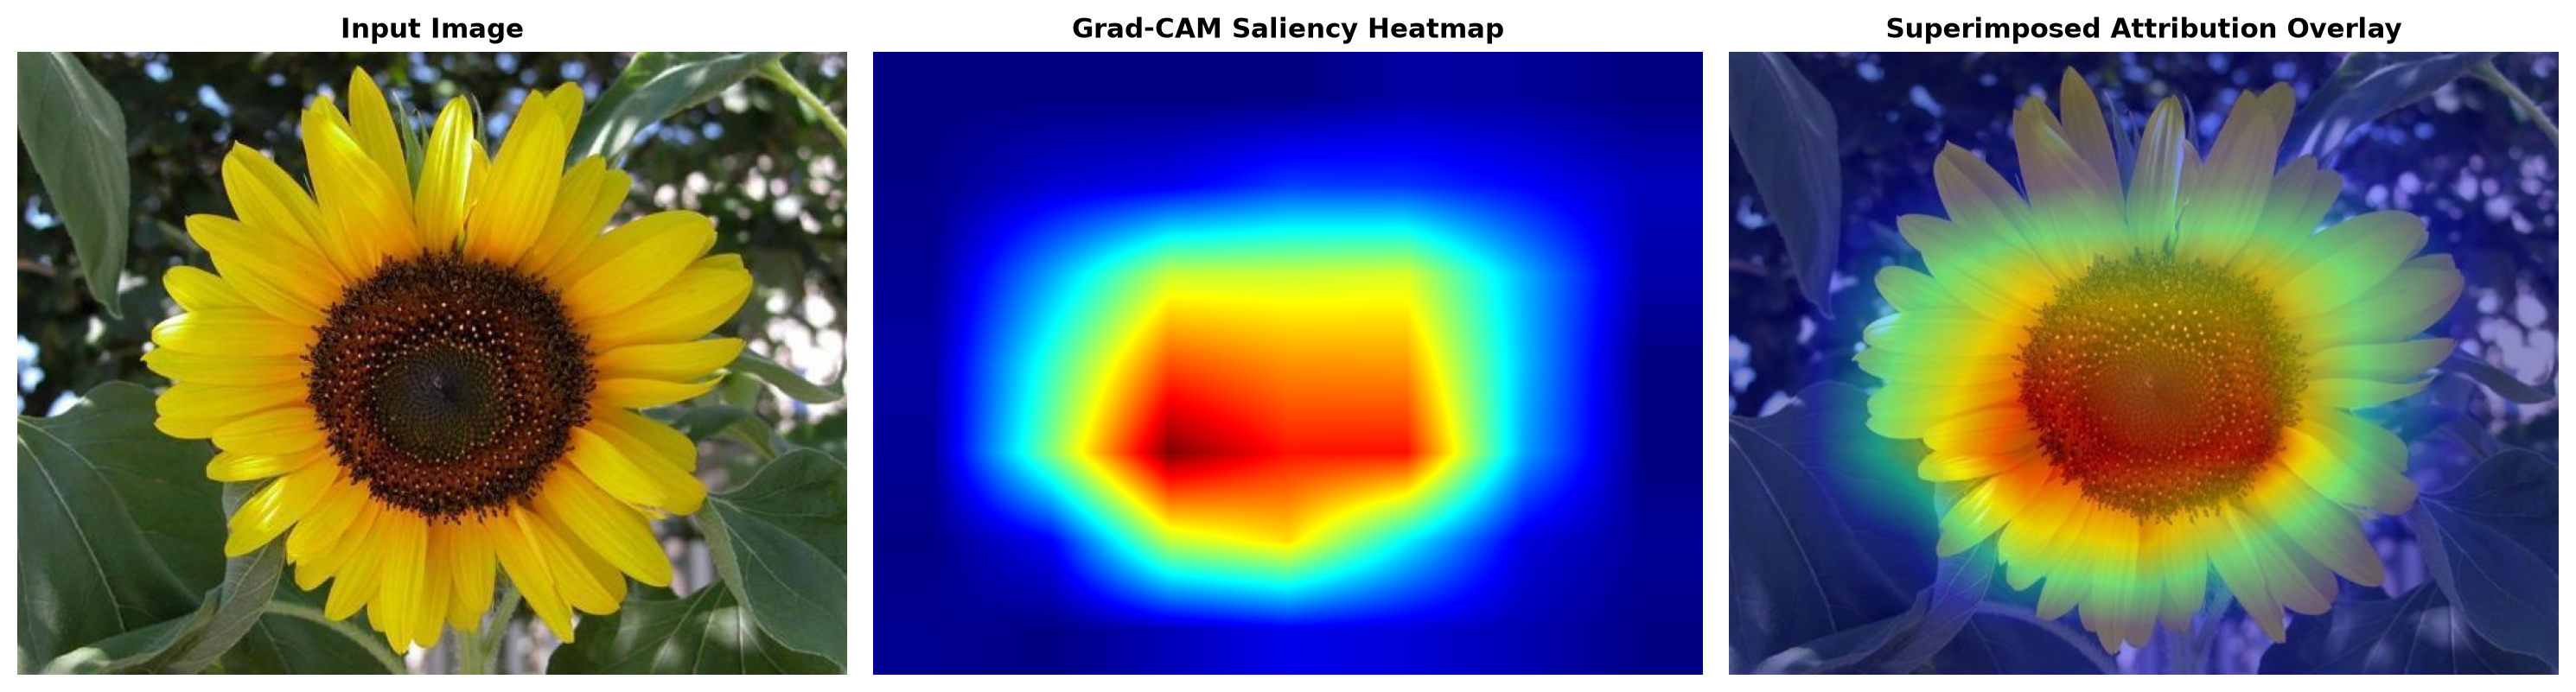

In [11]:
from src.gradcam import make_gradcam_heatmap, generate_gradcam_overlay

heatmap = make_gradcam_heatmap(arr, best_model, pred_index=top_idx)
colored_heatmap, overlay = generate_gradcam_overlay(pil_img, heatmap)

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 5))
ax1.imshow(pil_img)
ax1.set_title('Input Image', fontsize=11, fontweight='bold')
ax1.axis('off')

ax2.imshow(colored_heatmap)
ax2.set_title('Grad-CAM Saliency Heatmap', fontsize=11, fontweight='bold')
ax2.axis('off')

ax3.imshow(overlay)
ax3.set_title('Superimposed Attribution Overlay', fontsize=11, fontweight='bold')
ax3.axis('off')

plt.tight_layout()
plt.show()
